# EDA and Data Preprocessing

#	Section	Course checklist item
0	Load, set the test set aside

1	Data types	data type identification

2	Five-number summary	five-number summary

3	Missing values	missing values detection

4	Class balance	visualization

5	Feature distributions, apnea vs. normal	visualization (histogram, violin)

6	Outliers	outlier detection

7	Correlations	correlation analysis

8	PCA picture	(also PCA from the course list)

9	Preprocessing + save the clean table	handling missing/outliers, normalization, feature removal, feature engineering

In [51]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

features = pd.read_csv(ROOT / "data" / "processed" / "features.csv")

train = features[features.group != 'x'].copy()
test = features[features.group == 'x'].copy()

FEATS = ["n_beats", "frac_valid", "rr_mean", "rr_sdnn","rr_rmssd", "rr_pnn50","rr_min", "rr_max", "rr_range", "hr_mean"]

print(train.shape, test.shape)
train.head()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
(17045, 14) (17268, 14)


,n_beats,frac_valid,rr_mean,rr_sdnn,rr_rmssd,rr_pnn50,rr_min,rr_max,rr_range,hr_mean,record,minute,label,group
0,66,1.0,0.900152,60.038255,42.299300,27.692308,0.77,1.02,0.25,66.949906,a01,0,0,a
1,71,1.0,0.839155,46.035591,39.078675,18.571429,0.70,0.94,0.24,71.720335,a01,1,0,a
2,74,1.0,0.812838,80.690857,41.644286,16.438356,0.67,0.98,0.31,74.542158,a01,2,0,a
3,80,1.0,0.748375,60.868061,28.838266,10.126582,0.61,0.85,0.24,80.735180,a01,3,0,a
4,76,1.0,0.794737,45.883147,28.612352,8.000000,0.69,0.92,0.23,75.744081,a01,4,0,a


In [52]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 17045 entries, 0 to 17044
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   n_beats     17045 non-null  int64  
 1   frac_valid  17045 non-null  float64
 2   rr_mean     16978 non-null  float64
 3   rr_sdnn     16978 non-null  float64
 4   rr_rmssd    16978 non-null  float64
 5   rr_pnn50    16978 non-null  float64
 6   rr_min      16978 non-null  float64
 7   rr_max      16978 non-null  float64
 8   rr_range    16978 non-null  float64
 9   hr_mean     16978 non-null  float64
 10  record      17045 non-null  str    
 11  minute      17045 non-null  int64  
 12  label       17045 non-null  int64  
 13  group       17045 non-null  str    
dtypes: float64(9), int64(3), str(2)
memory usage: 1.9 MB


In [53]:
print(train[["record", "group"]].nunique())
print(train.label.value_counts())

record    35
group      3
dtype: int64
label
0    10531
1     6514
Name: count, dtype: int64


In [54]:
train[FEATS].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
n_beats,17045.0,65.895,9.927,0.000,60.000,65.000,72.000,112.000
frac_valid,17045.0,0.980,0.085,0.000,1.000,1.000,1.000,1.000
rr_mean,16978.0,0.920,0.120,0.487,0.833,0.924,1.002,1.652
rr_sdnn,16978.0,66.275,42.806,6.879,33.981,55.973,87.938,531.772
rr_rmssd,16978.0,44.503,38.664,6.699,19.406,32.235,56.796,477.982
rr_pnn50,16978.0,19.174,21.570,0.000,1.562,10.959,31.034,100.000
rr_min,16978.0,0.792,0.114,0.360,0.710,0.800,0.880,1.490
rr_max,16978.0,1.068,0.174,0.580,0.950,1.050,1.180,1.980
rr_range,16978.0,0.276,0.163,0.020,0.150,0.240,0.370,1.470
hr_mean,16978.0,66.827,9.162,36.620,60.305,65.273,72.513,127.531


#### Overall
17045 mins, 67 NaN value. 0.4%

frac_valid 98% -> true values and no suden jumps between beats

`rr_min` = 0.36, `rr_max` = 1.98 -> between our limit 0.3 & 2.0

`n_beats` max = 112 to much

#### Skewed features
`rr_sdnn` -> median 56, mean 66, max 532

`rr_rmssd` -> median 32, mean 45, max 478


In [55]:
na = train[FEATS].isna().sum()
print(na)
nan_rows = train[train.rr_mean.isna()]
print(nan_rows.record.value_counts())
print(nan_rows.label.value_counts())

n_beats        0
frac_valid     0
rr_mean       67
rr_sdnn       67
rr_rmssd      67
rr_pnn50      67
rr_min        67
rr_max        67
rr_range      67
hr_mean       67
dtype: int64
record
c04    18
c09    11
c01    10
c02     8
c10     8
b05     6
b04     5
a17     1
Name: count, dtype: int64
label
0    66
1     1
Name: count, dtype: int64


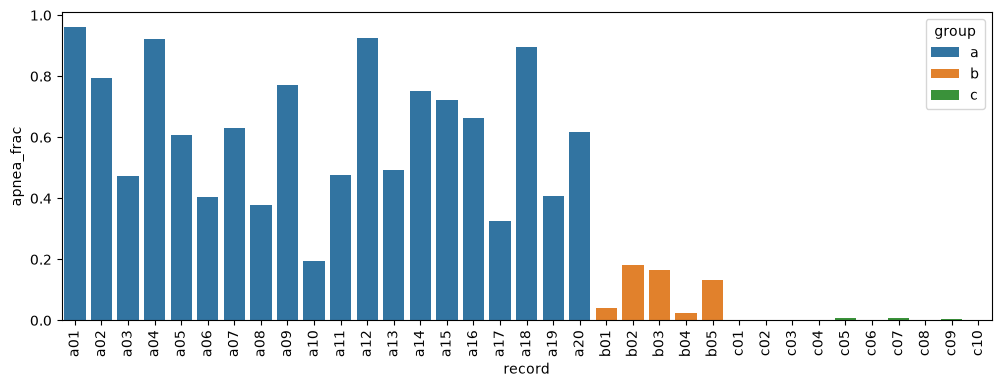

In [56]:
per_rec = train.groupby('record').agg(group = ('group', 'first'), apnea_frac = ('label', 'mean')).reset_index()
plt.figure(figsize=(12,4))
sns.barplot(data = per_rec, x='record', y='apnea_frac', hue='group', dodge=False)
plt.xticks(rotation = 90)
plt.savefig(FIG / 'class_balance_per_record.png')
plt.show()

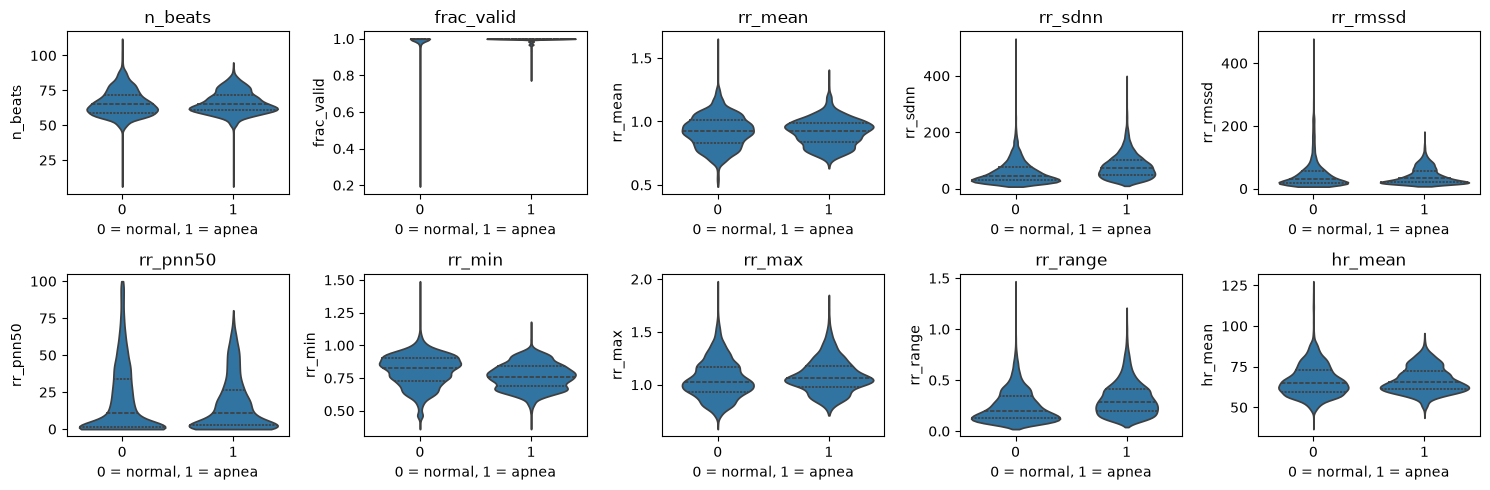

In [57]:
clean = train.dropna(subset=FEATS)
fig,axes = plt.subplots(2,5,figsize=(15,5))
for ax, col in zip(axes.flat, FEATS):
    sns.violinplot(data = clean, x='label', y=col, ax = ax, cut =0, inner = 'quartile')
    ax.set_title(col)
    ax.set_xlabel('0 = normal, 1 = apnea')

plt.tight_layout()
plt.savefig(FIG / "violins_by_label.png", dpi=150, bbox_inches="tight")
plt.show()

#### Results
`rr_sdnn` and `rr_range` -> apnea higher

`rr_min` -> apnea lower

`rr_max` -> apnea slighly higher

In [58]:
def iqr_out(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3-q1
    return ((s<q1-1.5*iqr) | (s>q3+1.5*iqr))

out = pd.DataFrame({
    'n_outliers': [iqr_out(clean[c]).sum() for c in FEATS],
    'pct': [iqr_out(clean[c]).mean() * 100 for c in FEATS],
    "pct_apnea_among_outliers": [clean.loc[iqr_out(clean[c]), "label"].mean() * 100 for c in FEATS],
}, index=FEATS).round(2)

out

,n_outliers,pct,pct_apnea_among_outliers
n_beats,153,0.90,7.19
frac_valid,2984,17.58,35.15
rr_mean,102,0.60,9.80
rr_sdnn,477,2.81,55.77
rr_rmssd,860,5.07,8.72
rr_pnn50,394,2.32,1.78
rr_min,36,0.21,8.33
rr_max,209,1.23,33.49
rr_range,323,1.90,60.06
hr_mean,146,0.86,7.53


In [59]:
print("minutes with > 100 beats ", (clean.n_beats > 100).sum())
print("minutes with < 80% valid intervals ", (clean.frac_valid < 0.8).sum())

minutes with > 100 beats  26
minutes with < 80% valid intervals  435


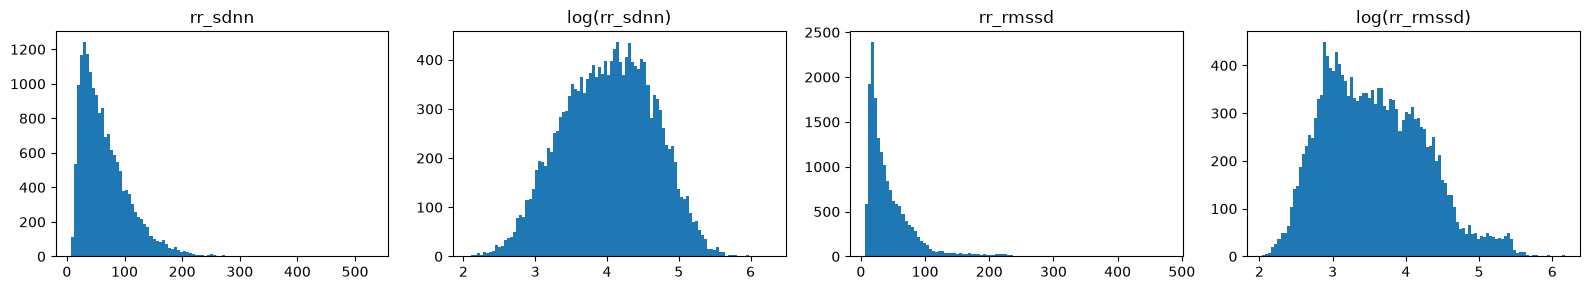

In [60]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for i, col in enumerate(["rr_sdnn", "rr_rmssd"]):
    axes[2*i].hist(clean[col], bins=100)
    axes[2*i].set_title(col)
    axes[2*i+1].hist(np.log1p(clean[col]), bins=100)
    axes[2*i+1].set_title(f"log({col})")
plt.tight_layout()
plt.savefig(FIG / "log_transform.png")
plt.show()

### Preprocessing

In [61]:
bad = ((clean.frac_valid < 0.8) | (clean.n_beats > 100)) #low qualit signals, and double detecttions
print(bad.sum(), 'minutes removed')
print(clean.loc[bad, 'label'].value_counts())
print(clean.loc[bad, 'record'].value_counts())

447 minutes removed
label
0    445
1      2
Name: count, dtype: int64
record
c04    294
b04     97
b05     31
a07      5
c06      3
a16      2
c02      2
c03      2
c10      2
a01      1
a03      1
a17      1
b01      1
c01      1
c05      1
c07      1
c08      1
c09      1
Name: count, dtype: int64


c04 total minutes: 482


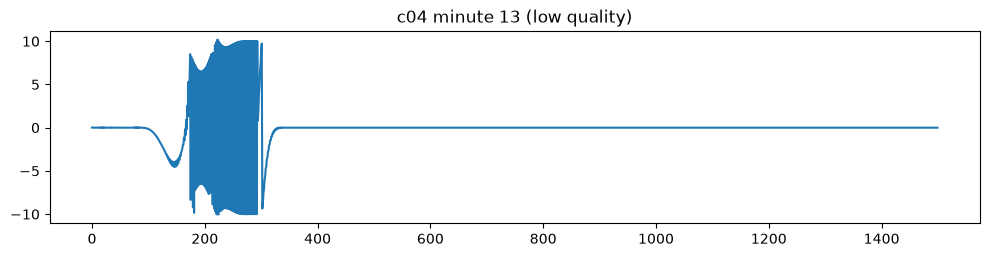

In [62]:
print("c04 total minutes:", (train.record == "c04").sum())
m = clean[(clean.record == "c04") & (clean.frac_valid < 0.8)].minute.iloc[0]
from src.data import load_ecg
ecg_c04 = load_ecg("c04")
plt.figure(figsize=(12, 2.5)); plt.plot(ecg_c04[m * 6000: m * 6000 + 1500])   # 15 s
plt.title(f"c04 minute {m} (low quality)"); plt.show()

noise

In [63]:
n_total = (train.record == "c04").sum()
print(f"c04: {n_total} minutes, {294} removed ({294 / n_total:.0%})")

c04: 482 minutes, 294 removed (61%)


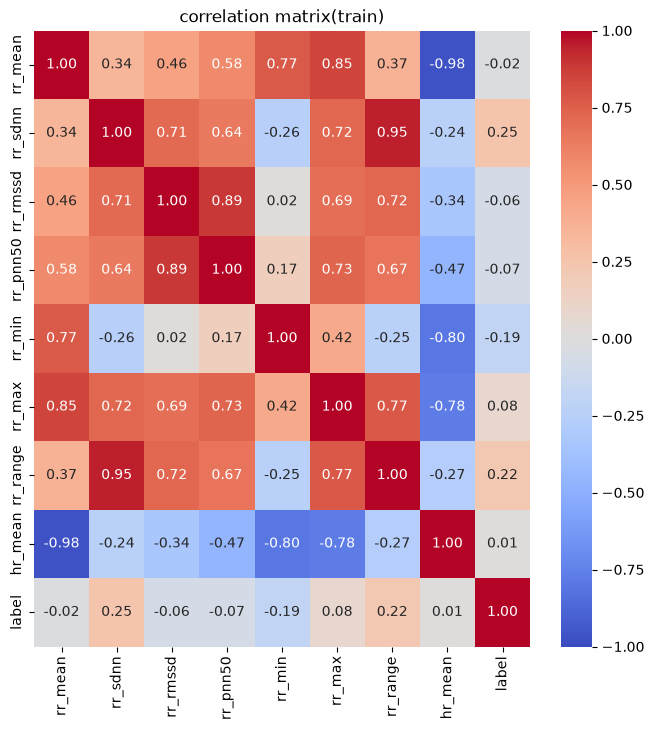

In [64]:
MODEL_FEATS = ["rr_mean", "rr_sdnn", "rr_rmssd", "rr_pnn50", "rr_min", "rr_max", "rr_range", "hr_mean"]

corr = clean[MODEL_FEATS + ["label"]].corr()
plt.figure(figsize=(8, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("correlation matrix(train)")
plt.savefig(FIG / "correlation.png", dpi=150, bbox_inches="tight")
plt.show()

#### Info
no single feature separates the classes. combining required

`rr_mean` and `hr_mean` same 0.98

`rr_sdnn` and `rr_range` 0.95, later

`rr_rmssd` and `rr_pnn50` 0.89

variance explained: [0.613 0.288]


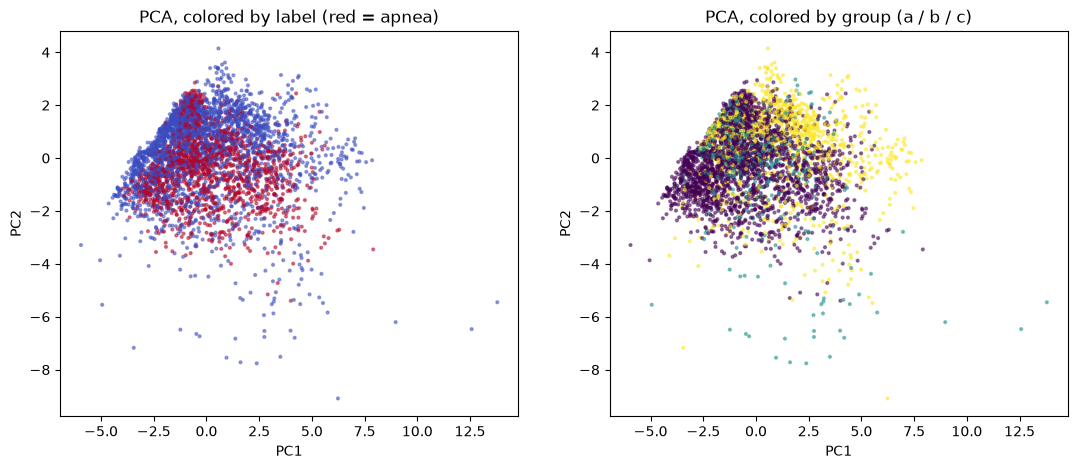

In [65]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = StandardScaler().fit_transform(clean[MODEL_FEATS])
pca = PCA(n_components=2).fit(X)
Z = pca.transform(X)
print("variance explained:", pca.explained_variance_ratio_.round(3))

sample = np.random.default_rng(0).choice(len(Z), 4000, replace=False)  # fewer dots = readable
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(Z[sample, 0], Z[sample, 1], c=clean.label.values[sample], cmap="coolwarm", s=4, alpha=0.5)
axes[0].set_title("PCA, colored by label (red = apnea)")
axes[1].scatter(Z[sample, 0], Z[sample, 1], c=clean.group.map({"a": 0, "b": 1, "c": 2}).values[sample],
                cmap="viridis", s=4, alpha=0.5)
axes[1].set_title("PCA, colored by group (a / b / c)")
for ax in axes: ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.savefig(FIG / "pca.png", dpi=150, bbox_inches="tight")
plt.show()

In [68]:
BASE = ["rr_mean", "rr_sdnn", "rr_rmssd", "rr_pnn50", "rr_min", "rr_max", "rr_range"]
LOG_FEATS = ["rr_sdnn", "rr_rmssd"]

def preprocess(df):
    df = df.sort_values(['record', 'minute' ]).copy()

    bad = df[BASE].isna().any(axis=1) | (df.frac_valid <0.8) | (df.n_beats > 100)
    df.loc[bad, BASE] = np.nan

    for c in LOG_FEATS:
        df[c] = np.log1p(df[c])

    #per patient z-score normalization
    g= df.groupby('record')[BASE]
    Z = [c+ '_z' for c in BASE]
    df[Z] = ((df[BASE] - g.transform('mean')) / g.transform('std')).values

    #average of 5 min around each minu
    CTX = [c+ '_ctx' for c in Z]
    df[CTX] = (df.groupby('record')[Z].transform(lambda s: s.rolling(5, center = True, min_periods = 1).mean()).values)

    df = df[~bad].drop(columns= ['hr_mean', 'n_beats', 'frac_valid'])
    return df

train_clean = preprocess(train)
test_clean = preprocess(test)

print(train.shape, ' -> ', train_clean.shape)
print(test.shape, ' -> ', test_clean.shape)
print('NAN: ', train_clean.isna().sum().sum(), test_clean.isna().sum().sum())

(17045, 14)  ->  (16531, 25)
(17268, 14)  ->  (16561, 25)
NAN:  0 0


3 feature sets. base, z-score, z-score+ctx

In [70]:
Z = [c + "_z" for c in BASE]; CTX = [c + "_ctx" for c in Z]
print(train_clean[BASE + Z + CTX + ["label"]].corr()["label"].drop("label").round(2).sort_values())

rr_min           -0.21
rr_min_z_ctx     -0.12
rr_min_z         -0.09
rr_pnn50         -0.02
rr_mean          -0.01
rr_rmssd          0.06
rr_max            0.11
rr_mean_z         0.13
rr_mean_z_ctx     0.15
rr_pnn50_z        0.17
rr_pnn50_z_ctx    0.21
rr_rmssd_z        0.22
rr_max_z          0.25
rr_rmssd_z_ctx    0.26
rr_range          0.26
rr_range_z        0.27
rr_max_z_ctx      0.28
rr_sdnn_z         0.32
rr_range_z_ctx    0.34
rr_sdnn           0.34
rr_sdnn_z_ctx     0.39
Name: label, dtype: float64


#### Analyzing feature changes

`rr_sdnn` went from 0.25 to `rr_sdnn_z_ctx` 0.39

almopst everywhere context with z-score


`rr_rmssd` and `rr_pnn50` went from 0.06 to 0.22, and -0.02 to 0.17 repectively. raw was almost useless. Here we did per-patient. In c(healthy) patients have high RMSSD. But within each patient, apnea minutes are more variable than that person's usual.

only in `rr_min` , z score worse than base. So neither version is best for every feature. We have to compare the feature sets individually.


In [71]:
out = ROOT / "data" / "processed"
train_clean.to_csv(out / "train_clean.csv", index=False)
test_clean.to_csv(out / "test_clean.csv", index=False)